# Predicting Online Shoppers' Purchase Intention from Browsing-Session Behavior: A Comparative Study of Imbalanced Classification Models

#### Nijendra Giri

AIT 620 | Final Project | October 25, 2026

**Abstract**

Online retailers tend to only convert a small share of their visits into actual sales, so, it is helpful for the shop to know early whether a session will end in actual purchase or not as it helps its limited effort of the shop to focus on the right place. This project uses the Online Shoppers Purchasing Intention data set from the UCI Machine Learning Repository (Sakar & Kastro, 2018), which describes 12,330 browsing sessions, of which 15.5% ended in a purchase. With six tables we did an exploratory analysis and five charts, then duplicate sessions were removed and the data were split into training and test sets. Evaluated on unseen sessions, with grid search and cross-validation, a baseline, logistic regression and a random forest were tuned. The random forest reached a ROC-AUC of 0.923 and a PR-AUC of 0.732 (baseline 0.156), and logistic regression performed similarly (0.925 and 0.680). Followed by exit rates and the time spent on product pages, the most important feature was the page value. 

**Keywords:** purchase intention, e-commerce analytics, class imbalance, random forest, gradient boosting, scikit-learn

## Table of Content

[Problem](#problem)  
[Data Understanding](#data_understanding)  
[Data Preparation](#data_preparation)  
[Modeling](#modeling)  
[Evaluation](#evaluation)  
[References](#references)

## Problem <a class="anchor" id="problem"></a>

Most visits to an online shop do not end in a purchase. The data we used here also shows us that roughly five out of six sessions end without a sale. A practical question is raised for a retailer that is can the behavior of a visitor during a session tell us whether the session will end in a purchase? If it can, the retailer could show a discount to a hesistant but promising visitor, offer live help, or avoid spending advertising money on sessions that are very unlikely to convert. Purchase prediction is therefore a classic business application of supervised learning (Sakar et al., 2019).

The problem is a **binary classification** task on **imbalanced** data: the positive class (purchase) is the minority. Imbalance makes the problem harder than it first appears, because a model that always predicts "no purchase" is right about 84% of the time yet has no business value (He & Garcia, 2009). Accuracy is therefore a poor yardstick, and this project relies on rank-based and precision-recall measures instead (Saito & Rehmsmeier, 2015).

The project follows the phases of the CRISP-DM process (Chapman et al., 2000), which map directly onto the sections of this notebook: *Problem*, *Data Understanding*, *Data Preparation*, *Modeling*, and *Evaluation*. It answers three research questions:

- **RQ1.** How well can a purchase be predicted from session behavior, compared with a no-skill baseline?
- **RQ2.** Which of three standard model families (logistic regression, random forest, gradient boosting) predicts best, and are the differences between them real or only noise?
- **RQ3.** Which information drives the predictions, how reliable are the predicted probabilities, and for which visitors does the model work less well?

**Experimental design.** Stratified by the target, the data are split once into a training set (80%) and a test set (20%). All choices, such as the preprocessing, the hyperparameters, and the decision threshold, are made on the training set only, using cross-validation (Kohavi, 1995).To estimate how the final models would perform on unseen sessions, at the end, the test set is used once. All experiments use scikit-learn (Pedregosa et al., 2011) and a fixed random seed, so the notebook can be re-run with the same results.

## Data Understanding<a class="anchor" id="data_understanding"></a>

### The Data Set
The experiment uses the **Online Shoppers Purchasing Intention** data set, which was donated to the UCI Machine Learning Repository by Sakar and Kastro (2018) and was first analyzed by Sakar et al. (2019). It is publicly available at <https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset> and is also mirrored on Kaggle. Rather than a clean benchmark, it is not one of the heavily used teaching data sets, and it contains real, heavily skewed behavioral data. 

Each of the 12,330 rows describes one **browsing session** on an e-commerce website. According to the data providers, the sessions belong to different users over a period of one year, so that the data do not favor a specific campaign, special day, user profile, or period (Sakar & Kastro, 2018). Stating whether the session ended with a purchase, the target variable, 'Revenue'. The 17 predictors fall into three groups:

1. **Page-visit counts and durations** for three page categories (administrative, informational, and product-related pages).
2. **Google Analytics metrics** for the visited pages: `BounceRates`, `ExitRates`, and `PageValues`.
3. **Context variables**: the closeness of the visit to a special day, the month, the operating system, browser, region, traffic source, visitor type, and whether the visit took place on a weekend.

### Environment Setup and Data Loading
So that all results are reproducible, the first code cell imports every library used in this notebook and fixes the random seed. Loading the data is second cell. The notebook is self-contained: it reads the CSV file from the same folder when it is availanle (as in the project's GitHub Repository) and otherwise downloads a public copy of the same UCI file.  

In [1]:
# --- Standard library and third-party imports ---
import sys
import platform
import warnings
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
import sklearn
from IPython.display import display

# --- Global settings: one seed everywhere keeps results reproducible ---
SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")          # keep the output readable
%matplotlib inline

# Show tables with three decimals and enough columns
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Consistent, colour-blind-friendly figure style
C_NO, C_YES = "#0072B2", "#D55E00"         # blue = no purchase, orange = purchase
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
})

def show(table, index=False):
    # Display a DataFrame as a clean table (3 decimals, thousands separators)
    styler = table.style.format(precision=3, thousands=",")
    display(styler if index else styler.hide(axis="index"))


# Record the software versions used (reproducibility)
print("Python      :", platform.python_version())
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)

Python      : 3.13.12
NumPy       : 2.5.3
pandas      : 3.0.5
scikit-learn: 1.9.0
matplotlib  : 3.11.1


In [2]:
# Name of the CSV file 
DATA_FILE = Path("online_shoppers_intention.csv")

# Backup: a public copy of the same UCI file, used only if the local file is
# missing. After uploading to GitHub
DATA_URLS = [
    "https://raw.githubusercontent.com/sidneykung/online_shopper_intentions/"
    "main/data/online_shoppers_intention.csv",
]


def load_data():
    """Return the raw dataset: the local file first, then the online copy."""
    if DATA_FILE.exists():
        print("Source: local file", DATA_FILE)
        return pd.read_csv(DATA_FILE)
    for url in DATA_URLS:
        try:
            data = pd.read_csv(url)
            print("Source:", url)
            return data
        except Exception as error:   # network or address problem
            print("Could not read", url, "->", error)
    raise FileNotFoundError(
        "Put online_shoppers_intention.csv in the notebook folder.")


raw = load_data()                    # keep the untouched data in `raw`
print("Rows, columns:", raw.shape)
display(raw.head())                  # first five rows as a quick look

Source: local file online_shoppers_intention.csv
Rows, columns: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.000,0,0.000,2,64.000,0.000,0.100,0.000,0.000,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.000,0,0.000,2,2.667,0.050,0.140,0.000,0.000,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.000,0,0.000,10,627.500,0.020,0.050,0.000,0.000,Feb,3,3,1,4,Returning_Visitor,True,False


### Data Dictionary
Table 1 documents the 17 predictors and the target variable. The three page-category pairs (`Administrative`, `Informational`, `ProductRelated`) record how many pages of that type were viewed and how long the visitor stayed on them. `BounceRates`, `ExitRates` and `PageValues` are metrics computed by Google Analytics for the pages in the session (Sakar et al., 2019).

**Table 1**

*Data Dictionary of the Online Shoppers Purchasing Intention Dataset*

In [3]:
# Build a small table that explains every variable (one row per variable):
# its name, its type and what it measures
dictionary = pd.DataFrame([
    ("Administrative", "Integer", "Number of account-management pages visited"),
    ("Administrative_Duration", "Numeric", "Time spent on administrative pages"),
    ("Informational", "Integer", "Number of informational pages visited (site, contact, address)"),
    ("Informational_Duration", "Numeric", "Time spent on informational pages"),
    ("ProductRelated", "Integer", "Number of product-related pages visited"),
    ("ProductRelated_Duration", "Numeric", "Time spent on product-related pages"),
    ("BounceRates", "Numeric (0-1)", "Average bounce rate of the visited pages (single-page exits)"),
    ("ExitRates", "Numeric (0-1)", "Average exit rate of the visited pages (last page in a session)"),
    ("PageValues", "Numeric", "Average page value of the visited pages (Google Analytics)"),
    ("SpecialDay", "Numeric (0-1)", "Closeness of the visit to a special day (e.g., Valentine's Day)"),
    ("Month", "Categorical", "Month of the visit"),
    ("OperatingSystems", "Categorical (code)", "Operating-system code of the visitor"),
    ("Browser", "Categorical (code)", "Browser code of the visitor"),
    ("Region", "Categorical (code)", "Geographic region code of the visitor"),
    ("TrafficType", "Categorical (code)", "Traffic-source code (how the visitor arrived)"),
    ("VisitorType", "Categorical", "New_Visitor, Returning_Visitor or Other"),
    ("Weekend", "Boolean", "Whether the visit happened on a weekend"),
    ("Revenue", "Boolean (target)", "Whether the session ended with a purchase"),
], columns=["Variable", "Type", "Description"])

show(dictionary)    # helper from the first cell: shows a clean table

Variable,Type,Description
Administrative,Integer,Number of account-management pages visited
Administrative_Duration,Numeric,Time spent on administrative pages
Informational,Integer,"Number of informational pages visited (site, contact, address)"
Informational_Duration,Numeric,Time spent on informational pages
ProductRelated,Integer,Number of product-related pages visited
ProductRelated_Duration,Numeric,Time spent on product-related pages
BounceRates,Numeric (0-1),Average bounce rate of the visited pages (single-page exits)
ExitRates,Numeric (0-1),Average exit rate of the visited pages (last page in a session)
PageValues,Numeric,Average page value of the visited pages (Google Analytics)
SpecialDay,Numeric (0-1),"Closeness of the visit to a special day (e.g., Valentine's Day)"


### Dataset Overview and Data-Quality Checks
Before any modeling we verify the size of the data, missing values, duplicate rows and label consistency. Table 2 summarizes the main characteristics.

**Table 2**

*Overview of the Raw Dataset*

In [4]:
# Lists of column names
num_cols = ["Administrative", "Administrative_Duration", "Informational",
            "Informational_Duration", "ProductRelated",
            "ProductRelated_Duration", "BounceRates", "ExitRates",
            "PageValues", "SpecialDay"]
cat_cols = ["Month", "OperatingSystems", "Browser", "Region",
            "TrafficType", "VisitorType", "Weekend"]

# Number of sessions that ended in a purchase (True counts as 1)
n_pos = int(raw["Revenue"].sum())

# Build the overview table: one characteristic per row
overview = pd.DataFrame({
    "Characteristic": [
        "Sessions (rows)", "Variables (columns)", "Numeric predictors",
        "Categorical predictors", "Missing values", "Exact duplicate rows",
        "Sessions ending in a purchase", "Sessions without a purchase",
        "Purchase rate"],
    "Value": [
        f"{raw.shape[0]:,}", f"{raw.shape[1]}", f"{len(num_cols)}",
        f"{len(cat_cols)}", f"{int(raw.isnull().sum().sum())}",
        f"{int(raw.duplicated().sum())}", f"{n_pos:,}",
        f"{raw.shape[0] - n_pos:,}", f"{n_pos / raw.shape[0]:.1%}"],
})
show(overview)

Characteristic,Value
Sessions (rows),"12,330"
Variables (columns),18
Numeric predictors,10
Categorical predictors,7
Missing values,0
Exact duplicate rows,125
Sessions ending in a purchase,"1,908"
Sessions without a purchase,"10,422"
Purchase rate,15.5%


In [5]:
# Detailed data-quality checks, printed one by one
print("Missing values per column (should all be 0):")
print(raw.isnull().sum().loc[lambda s: s > 0])
print("Total missing values:", int(raw.isnull().sum().sum()))

print("\nExact duplicate rows:", int(raw.duplicated().sum()))

print("\nMonth labels found:", sorted(raw["Month"].unique()))
print("Note: 'June' is spelled out while the other months use 3 letters.")
print("January and April do not appear in the data at all.")

neg = (raw[num_cols] < 0).sum().sum()
print("\nNegative values in numeric columns:", int(neg))

# Total time spent in a session = the sum of the three duration columns
dur = (raw["Administrative_Duration"] + raw["Informational_Duration"]
       + raw["ProductRelated_Duration"])
print("Sessions with zero total time:", int((dur == 0).sum()),
      f"({(dur == 0).mean():.1%})")
print("BounceRates range:", raw["BounceRates"].min(), "to",
      raw["BounceRates"].max())
print("ExitRates range:  ", raw["ExitRates"].min(), "to",
      raw["ExitRates"].max())

Missing values per column (should all be 0):
Series([], dtype: int64)
Total missing values: 0

Exact duplicate rows: 125

Month labels found: ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
Note: 'June' is spelled out while the other months use 3 letters.
January and April do not appear in the data at all.

Negative values in numeric columns: 0
Sessions with zero total time: 720 (5.8%)
BounceRates range: 0.0 to 0.2
ExitRates range:   0.0 to 0.2


### Descriptive Statistics
Table 3 describes the numeric predictors and Table 4 the categorical predictors.

**Table 3**

*Descriptive Statistics of the Numeric Predictors*

In [6]:
# Summary statistics (count, mean, std, min, quartiles, max) per numeric column
desc = raw[num_cols].describe().T

# Skewness shows how lopsided each distribution is (0 = symmetric)
desc["skewness"] = raw[num_cols].skew()

display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,skewness
Administrative,"12,330.000",2.315,3.322,0.000,0.000,1.000,4.000,27.000,1.960
Administrative_Duration,"12,330.000",80.819,176.779,0.000,0.000,7.500,93.256,"3,398.750",5.616
Informational,"12,330.000",0.504,1.270,0.000,0.000,0.000,0.000,24.000,4.036
Informational_Duration,"12,330.000",34.472,140.749,0.000,0.000,0.000,0.000,"2,549.375",7.579
ProductRelated,"12,330.000",31.731,44.476,0.000,7.000,18.000,38.000,705.000,4.342
ProductRelated_Duration,"12,330.000","1,194.746","1,913.669",0.000,184.138,598.937,"1,464.157","63,973.522",7.263
BounceRates,"12,330.000",0.022,0.048,0.000,0.000,0.003,0.017,0.200,2.948
ExitRates,"12,330.000",0.043,0.049,0.000,0.014,0.025,0.050,0.200,2.149
PageValues,"12,330.000",5.889,18.568,0.000,0.000,0.000,0.000,361.764,6.383
SpecialDay,"12,330.000",0.061,0.199,0.000,0.000,0.000,0.000,1.000,3.303


**Table 4**

*Summary of the Categorical Predictors*

In [7]:
rows = []
for col in cat_cols:
    counts = raw[col].value_counts()          # how often each category appears
    rows.append({"Variable": col,
                 "Distinct values": raw[col].nunique(),
                 "Most frequent value": str(counts.index[0]),
                 "Share of sessions": f"{counts.iloc[0] / len(raw):.1%}"})
show(pd.DataFrame(rows))

Variable,Distinct values,Most frequent value,Share of sessions
Month,10,May,27.3%
OperatingSystems,8,2,53.5%
Browser,13,2,64.6%
Region,9,1,38.8%
TrafficType,20,2,31.7%
VisitorType,3,Returning_Visitor,85.6%
Weekend,2,False,76.7%


**Interpretation.** We can see in Table 3 that nearly every count and duration is strongly right-skewed (skewness between 1.96 and 7.58). We can verify that the mean is more larger than the median, and the maximum is far from the thrid quartile. To give an example: the longest 'ProductRelated_Duration' (63,974 seconds, about 17.8 hours) is roughly 107 times the median of 599 seconds. For more than three quarters of the session (77.9%) 'PageValues' is zero. There are two consequences for these shapes for the modeling: one is the heavy tails are tamed with logarithmic transformation for the linear model, and the zero-inflated 'PageValues' suggests a binary "has a page value" feature. Table 4 demonstrates that the categorical codes which are all these operating system, browser, region, and traffic type) have many levels, some of which are very rare. Which groups rare categories, with a minimum frequency, they are therefore one-hot encoded. 

**Table 5**

*Association Between the Numeric Predictors and Purchase*

In [8]:
# Split the sessions into buyers and non-buyers
buy = raw["Revenue"] == 1

rows = []
for col in num_cols:
    a, b = raw.loc[buy, col], raw.loc[~buy, col]     # values of buyers / non-buyers
    # Mann-Whitney U test: do buyers tend to have higher or lower values
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({
        "Predictor": col,
        "Median (purchase)": a.median(),
        "Median (no purchase)": b.median(),
        #divided by the number of buyer/non-buyer pairs = probability of superiority
        "Probability of superiority": u.statistic / (len(a) * len(b)),
        "p-value": "< 0.001" if u.pvalue < 0.001 else f"{u.pvalue:.3f}",
    })

# Sort by how far each value is from 0.5 (= no relationship), strongest first
table5 = (pd.DataFrame(rows)
          .assign(strength=lambda t: (t["Probability of superiority"] - 0.5).abs())
          .sort_values("strength", ascending=False).drop(columns="strength"))
show(table5)

Predictor,Median (purchase),Median (no purchase),Probability of superiority,p-value
PageValues,16.758,0.000,0.863,< 0.001
ExitRates,0.016,0.029,0.297,< 0.001
ProductRelated_Duration,"1,109.906",510.190,0.673,< 0.001
ProductRelated,29.000,16.000,0.658,< 0.001
Administrative,2.000,0.000,0.627,< 0.001
Administrative_Duration,52.367,0.000,0.623,< 0.001
BounceRates,0.000,0.004,0.387,< 0.001
Informational,0.000,0.000,0.565,< 0.001
Informational_Duration,0.000,0.000,0.562,< 0.001
SpecialDay,0.000,0.000,0.464,< 0.001


**Table 6**

*Association Between the Categorical Predictors and Purchase*

In [9]:
rows = []
for col in cat_cols + ["SpecialDay"]:
    # Cross-tabulate the predictor against the purchase outcome
    table = pd.crosstab(raw[col], raw["Revenue"])
    # Chi-square test of independence
    chi2, p, dof, _ = stats.chi2_contingency(table)
    # Cramér's V: effect size from 0 (no link) to 1 (perfect link)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({"Predictor": col, "Chi-square": chi2, "df": dof,
                 "Cramer's V": cramers_v,
                 "p-value": "< 0.001" if p < 0.001 else f"{p:.3f}"})

table6 = pd.DataFrame(rows).sort_values("Cramer's V", ascending=False)
show(table6)

Predictor,Chi-square,df,Cramer's V,p-value
Month,384.935,9,0.177,< 0.001
TrafficType,373.146,19,0.174,< 0.001
VisitorType,135.252,2,0.105,< 0.001
SpecialDay,96.077,5,0.088,< 0.001
OperatingSystems,75.027,7,0.078,< 0.001
Browser,27.715,12,0.047,0.006
Weekend,10.391,1,0.029,0.001
Region,9.253,8,0.027,0.321


**Interpretation.** For the numeric predictors (Table 5), the probability of superiority is the chance that a randomly chosen purchasing session has a higher value than a randomly chosen non-purchasing session (0.5 means no difference; Mann & Whitney, 1947). It is more robust than a mean comparison for skewed data. `PageValues` stands far above the others (0.863), followed by the product-page measures (`ProductRelated_Duration` 0.673 and `ProductRelated` 0.658) and the administrative pages (about 0.62). Purchasing sessions have lower `ExitRates` (0.297) and `BounceRates` (0.387), which means that buyers rarely leave on the first or last page of their visit. All p-values are below 0.001, but with 12,330 sessions even small effects are significant, so the *size* of the effect is more informative than the p-value.

For the categorical predictors (Table 6), Cramér's V (Cramér, 1946) measures the strength of association from 0 to 1. `Month` (0.177) and `TrafficType` (0.174) are the strongest, followed by `VisitorType` (0.105). `Region` is the only variable with no detectable association with the purchase (p = 0.321). All associations are weak to modest in size, which suggests that behavioral measures, not demographics or technology, carry most of the signal.

### Exploratory Data Analysis: Charts
The following six figures explore the target, the calendar and visitor effects, the behavioral features, and the relationships between them.

**Figure 1**

*Distribution of the Target Variable (Revenue)*

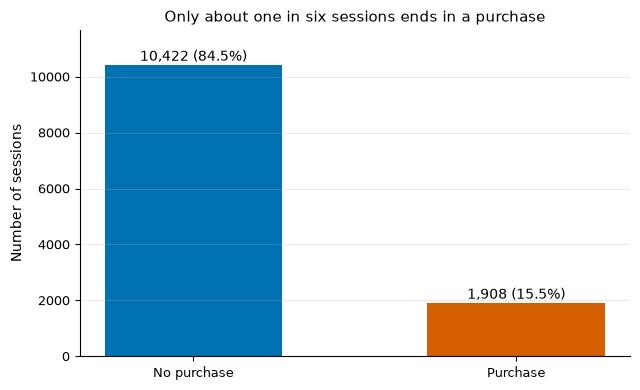

In [10]:
# Count sessions without (0/False) and with (1/True) a purchase
counts = raw["Revenue"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(["No purchase", "Purchase"], counts.values,
              color=[C_NO, C_YES], width=0.55)

# Write the count and the percentage above each bar
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 150,
            f"{value:,} ({value / counts.sum():.1%})", ha="center", fontsize=10)

ax.set_ylabel("Number of sessions")
ax.set_title("Only about one in six sessions ends in a purchase")
ax.set_ylim(0, counts.max() * 1.12)     # leave room for the labels
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Interpretation.** The target is imbalanced: 1,908 of the 12,330 sessions (15.5%) end in a purchase and 10,422 do not. A classifier that always answers "no purchase" would reach 84.5% accuracy without finding a single buyer. For this reason, the evaluation uses average precision, recall, and the Matthews correlation coefficient in addition to accuracy, and the models are trained with class weights.

**Figure 2**

*Session Volume and Purchase Rate by Month*

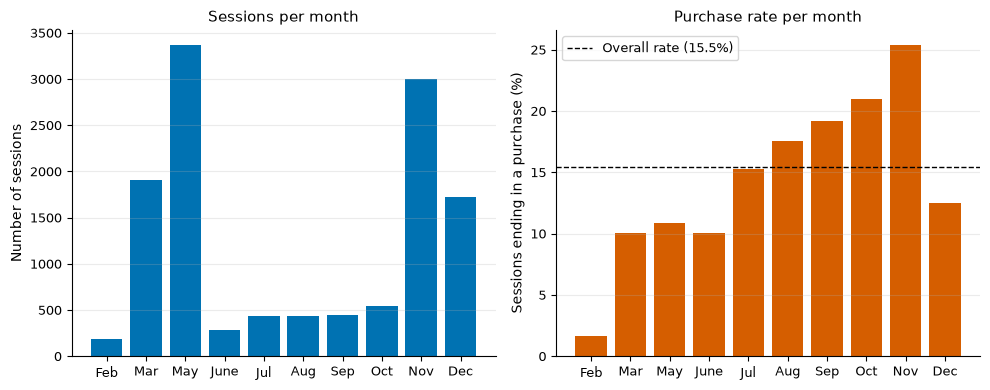

In [11]:
# Months in calendar order ('June' is spelled out in the raw data)
order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Number of sessions and purchase rate for each month
by_month = (raw.groupby("Month")["Revenue"].agg(["size", "mean"])
            .reindex(order))
overall = raw["Revenue"].mean()          # overall purchase rate (15.5%)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Left chart: how many sessions each month
axes[0].bar(by_month.index, by_month["size"], color=C_NO)
axes[0].set_title("Sessions per month")
axes[0].set_ylabel("Number of sessions")
axes[0].grid(axis="x", visible=False)

# Right chart: purchase rate per month, with the overall rate as a dashed line
axes[1].bar(by_month.index, by_month["mean"] * 100, color=C_YES)
axes[1].axhline(overall * 100, color="black", ls="--", lw=1,
                label=f"Overall rate ({overall:.1%})")
axes[1].set_title("Purchase rate per month")
axes[1].set_ylabel("Sessions ending in a purchase (%)")
axes[1].legend()
axes[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

**Interpretation.** The behavior of purchase is strongly seasonal. Highest purchase is by far November with purchase rate (25.4% of 2998 sessions), followed by October (20.9%) and September (19.2%). Converting only 10.9% in contrast, the busiest month is May, and February has just 184 sessions with a purchase rate of 1.6%. Missing from the data altogether is January and April. We can say that actually seasonality matters but the months are unevenly convered and their sample sizes differ greatly, which is a limitation that is discussed in the conclusion. 

**Figure 4**

*Behavioral Features by Purchase Outcome (log scale)*

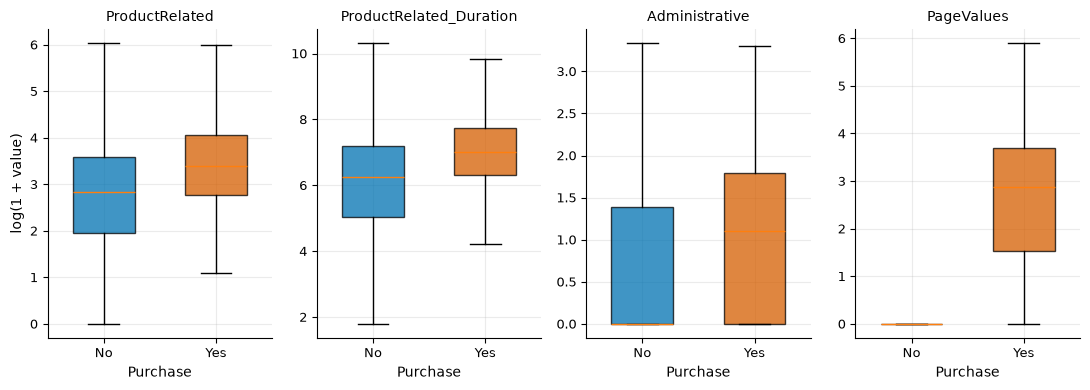

In [12]:
feats = ["ProductRelated", "ProductRelated_Duration", "Administrative",
         "PageValues"]
fig, axes = plt.subplots(1, 4, figsize=(11, 4))
for ax, col in zip(axes, feats):
    # log(1 + x) makes the skewed values easier to compare
    data = [np.log1p(raw.loc[raw["Revenue"] == v, col]) for v in (0, 1)]
    box = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["No", "Yes"])
    for patch, color in zip(box["boxes"], [C_NO, C_YES]):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Purchase")
axes[0].set_ylabel("log(1 + value)")
plt.tight_layout()
plt.show()

Purchasing sessions view more product pages, spend longer on them and have much higher `PageValues` (median 16.76 versus 0, Table 5). The distributions overlap, so no single variable separates the classes perfectly.

**Figure 5**

*Purchase Rate by Page Value*

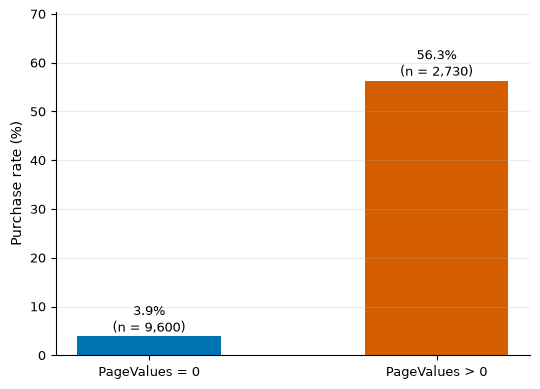

In [13]:
# Purchase rate when PageValues is zero versus above zero
pv = raw.groupby(raw["PageValues"] > 0)["Revenue"].agg(["size", "mean"])

fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(["PageValues = 0", "PageValues > 0"], pv["mean"] * 100,
              color=[C_NO, C_YES], width=0.5)
for bar, n, rate in zip(bars, pv["size"], pv["mean"]):
    ax.text(bar.get_x() + bar.get_width() / 2, rate * 100 + 1,
            f"{rate:.1%}\n(n = {n:,})", ha="center", fontsize=9)
ax.set_ylabel("Purchase rate (%)")
ax.set_ylim(0, pv["mean"].max() * 100 * 1.25)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Sessions with a positive `PageValues` end in a purchase 56.3% of the time, against 3.9% otherwise, a factor of about 14. `PageValues` is computed by Google Analytics from the revenue of visited pages, so it is a very strong but partly outcome-related signal.

**Summary of the EDA.** The target is imbalanced (15.5% purchases), most counts and durations are strongly right-skewed, `PageValues` is the strongest single signal, and the purchase rate differs by month and visitor type.

## Data Preparation<a class="anchor" id="data_preparation"></a>

There are three steps of data preparation. Because of the reason that the same session could otherwise appear in both the training and the test set, first, the 125 exact duplicate rows are removed, which would make the test results too optimistic. So that both keep the same purchase rate, stratified by the target, second, the data are split into a training set (80%) and a test set (20%). Third, the predictors are transformed inside a scikit-learn pipeline so that the transformations are learned from the training data only, which prevents data leakage (Pedregosa et al., 2011): the skewed counts and durations are log-transformed and standardized (the distributions in Table 3 are strongly right-skewed), the rate variables are standardized, and the categorical variables are one-hot encoded. The label `June` is left as it is, since it is only a naming difference.

In [14]:
# Imports for the data-preparation and modeling steps
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

# Remove exact duplicate rows
df = raw.drop_duplicates().reset_index(drop=True)

# Turn the True/False columns into 1/0 so that models can use them
df["Weekend"] = df["Weekend"].astype(int)
df["Revenue"] = df["Revenue"].astype(int)

print("Rows before / after removing duplicates:", raw.shape[0], "/", df.shape[0])
print("Purchase rate after cleaning: {:.2%}".format(df["Revenue"].mean()))

Rows before / after removing duplicates: 12330 / 12205
Purchase rate after cleaning: 15.63%


In [15]:
# Separate the predictors (X) from the target (y)
X = df.drop(columns="Revenue")
y = df["Revenue"]

# 80% training, 20% test; stratify keeps the same purchase rate in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Training set:", X_train.shape, " purchase rate {:.2%}".format(y_train.mean()))
print("Test set:    ", X_test.shape, " purchase rate {:.2%}".format(y_test.mean()))

Training set: (9764, 17)  purchase rate 15.63%
Test set:     (2441, 17)  purchase rate 15.65%


In [16]:
# Columns grouped by the transformation they need
skewed_cols = ["Administrative", "Administrative_Duration", "Informational",
               "Informational_Duration", "ProductRelated",
               "ProductRelated_Duration", "PageValues"]     # log, then scale
rate_cols = ["BounceRates", "ExitRates", "SpecialDay", "Weekend"]  # scale only
category_cols = ["Month", "OperatingSystems", "Browser", "Region",
                 "TrafficType", "VisitorType"]                # one-hot encode

preprocessor = ColumnTransformer([
    # log(1 + x) reduces the strong skew, then standardize to mean 0, std 1
    ("log", Pipeline([("log", FunctionTransformer(np.log1p,
                                                  feature_names_out="one-to-one")),
                      ("scale", StandardScaler())]), skewed_cols),
    ("rate", StandardScaler(), rate_cols),
    # one 0/1 column per category; unseen categories in new data are ignored
    ("cat", OneHotEncoder(handle_unknown="ignore"), category_cols),
])
print("Preprocessing defined for", len(skewed_cols) + len(rate_cols)
      + len(category_cols), "predictors.")

Preprocessing defined for 17 predictors.


## Modeling<a class="anchor" id="modeling"></a>

Three models are compared. A **baseline** showing what any useful model must beat that always predicts the training purchase rate. **Logistic regression** is a natural benchmark and it is a simple, interpretable linear model. A **random forest** (Breiman, 2001) is robust to outliers, that is an ensemble of decision trees also that captures nonlinear effects as well as interactions. Both models use balanced class weights, because only about 16% of the session end in a purchase which make mistakes on the rare purchase class more costly during training (He & Garcia, 2009). 

The parameters are chosen with a grid search and 5-fold cross-validation on the training set only (Kohavi, 1995). The search maximizes the *average precision*, the area under the precision-recall curve, which is more informative than accuracy for imbalanced data (Saito & Rehmsmeier, 2015). The searched parameters are the regularization strength `C` for logistic regression (0.01, 0.1, 1, 10), and the maximum depth (6, 10, no limit) and the minimum leaf size (1, 5) for the random forest with 200 trees. The test set is not used here.

**Table 7**

*Cross-Validation Results and Selected Parameters*

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Each entry: (model, parameter grid to search). The baseline has no grid.
models = {
    "Baseline (prior)": (DummyClassifier(strategy="prior"), None),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"clf__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample",
                               random_state=SEED, n_jobs=-1),
        {"clf__n_estimators": [200], "clf__max_depth": [6, 10, None],
         "clf__min_samples_leaf": [1, 5]}),
}

fitted, rows = {}, []
for name, (estimator, grid) in models.items():
    # Pipeline = preprocessing followed by the model, so that the test data
    # later go through exactly the same steps
    pipe = Pipeline([("pre", preprocessor), ("clf", estimator)])
    if grid is None:
        pipe.fit(X_train, y_train)
        fitted[name] = pipe
        rows.append({"Model": name, "Best CV average precision": "n/a",
                     "Selected parameters": "predicts the training purchase rate"})
    else:
        # Try every parameter combination with 5-fold cross-validation
        search = GridSearchCV(pipe, grid, scoring="average_precision",
                              cv=5, n_jobs=-1)
        search.fit(X_train, y_train)
        fitted[name] = search.best_estimator_
        params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
        rows.append({"Model": name,
                     "Best CV average precision": f"{search.best_score_:.3f}",
                     "Selected parameters": str(params)})

cv_table = pd.DataFrame(rows)
show(cv_table)

Model,Best CV average precision,Selected parameters
Baseline (prior),n/a,predicts the training purchase rate
Logistic Regression,0.667,{'C': 0.01}
Random Forest,0.741,"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}"


## Evaluation<a class="anchor" id="evaluation"></a>

The models are now evaluated on the 2,441 test sessions, which were not used for preprocessing or tuning. Accuracy alone is misleading here, because a model that always predicts "no purchase" is right about 84% of the time. Therefore precision, recall and the F1-score for the purchase class are reported, together with the ROC-AUC and the PR-AUC (average precision), which measure how well a model ranks buyers above non-buyers regardless of any threshold (Saito & Rehmsmeier, 2015). The PR-AUC of the baseline equals the purchase rate (about 0.156), so any useful model must be well above it.

**Table 8**

*Test-Set Performance of the Models*

In [18]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)

rows = []
for name, model in fitted.items():
    proba = model.predict_proba(X_test)[:, 1]   # predicted purchase probability
    pred = model.predict(X_test)                # predicted class (0 or 1)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred),
                 "F1-score": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba),
                 "PR-AUC": average_precision_score(y_test, proba)})

results = pd.DataFrame(rows)
show(results)

Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Baseline (prior),0.844,0.000,0.000,0.000,0.500,0.156
Logistic Regression,0.880,0.586,0.801,0.677,0.925,0.680
Random Forest,0.901,0.759,0.537,0.629,0.923,0.732


**Figure 6**

*ROC Curves of the Models on the Test Set*

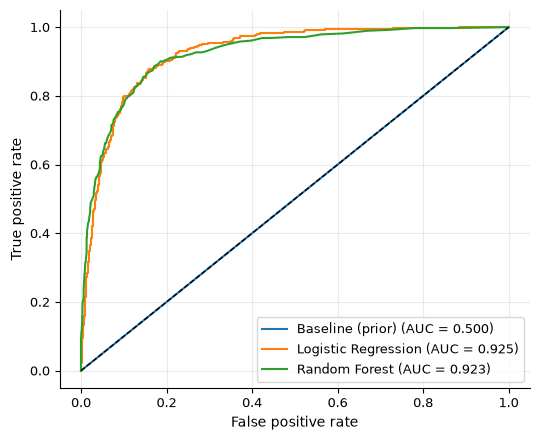

In [19]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for name, model in fitted.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)       # false/true positive rates
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)             # diagonal = random guessing
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Figure 7**

*Confusion Matrix of the Random Forest on the Test Set*

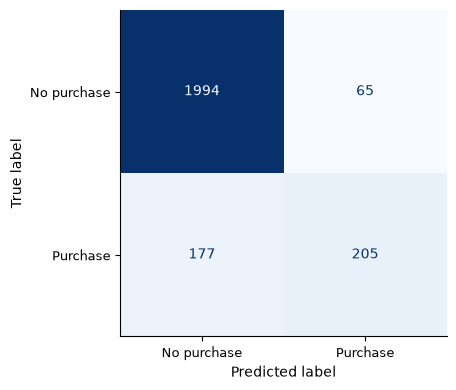

True negatives: 1,994  False positives: 65  False negatives: 177  True positives: 205


In [20]:
best_model = fitted["Random Forest"]            # the model with the best CV score

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_model.predict(X_test),
    display_labels=["No purchase", "Purchase"], cmap="Blues",
    ax=ax, colorbar=False)
ax.grid(False)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, best_model.predict(X_test)).ravel()
print(f"True negatives: {tn:,}  False positives: {fp:,}  "
      f"False negatives: {fn:,}  True positives: {tp:,}")

**Figure 8**

*Ten Most Important Features of the Random Forest*

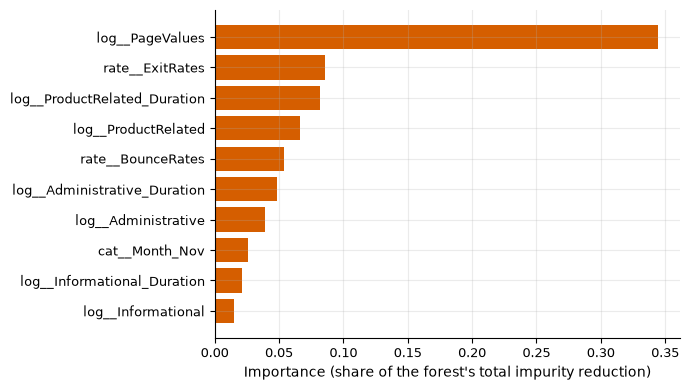

In [21]:
# Feature names after preprocessing (one-hot columns have one name per category)
feature_names = best_model.named_steps["pre"].get_feature_names_out()
importance = pd.Series(best_model.named_steps["clf"].feature_importances_,
                       index=feature_names).sort_values().tail(10)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance.values, color=C_YES)
ax.set_xlabel("Importance (share of the forest's total impurity reduction)")
plt.tight_layout()
plt.show()

`PageValues` is by far the most important feature (about 0.34), followed by `ExitRates` (about 0.09) and the time spent on product pages (about 0.08). Page value, exit behavior and product-page engagement therefore carry most of the information, which agrees with the association tests in Tables 5 and 6. Impurity-based importance can favor variables with many distinct values, so the ranking should be read as a guide, not as proof of cause.

### Conclusions
The experiment shows that a purchase can be predicted well from session behavior. On 2,441 unseen sessions, the random forest, selected by cross-validation, reached a ROC-AUC of 0.923 and a PR-AUC of 0.732, compared with 0.500 and 0.156 for the baseline. Logistic regression performed almost as well (ROC-AUC 0.925, PR-AUC 0.680). The two models differ in their trade-off: the random forest is more precise (0.759) and logistic regression finds more buyers (recall 0.801). `PageValues`, the exit rate and the time spent on product pages were the most important features, and the exploratory analysis showed that the purchase rate also varies strongly by month (highest in November) and by visitor type (higher for new visitors).

**Limitations.** The data come from one online shop over one year, and January and April are missing, so the results may not transfer to other shops or seasons. `PageValues` is computed by Google Analytics from the revenue of visited pages and may therefore not be available early in a session. The traffic, browser and region codes are anonymized, so they cannot be interpreted. The models were tuned with small parameter grids and evaluated with the default decision threshold only.

**Future work.** Future work could tune the decision threshold for a specific business cost, repeat the analysis without `PageValues`, test the models on later months than the ones used for training, and compare additional model families such as gradient boosting.

## References<a class="anchor" id="references"></a>

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS.

Cramér, H. (1946). *Mathematical methods of statistics*. Princeton University Press.

He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering, 21*(9), 1263–1284. https://doi.org/10.1109/TKDE.2008.239

Kohavi, R. (1995). A study of cross-validation and bootstrap for accuracy estimation and model selection. In *Proceedings of the 14th International Joint Conference on Artificial Intelligence* (Vol. 2, pp. 1137–1143). Morgan Kaufmann.

Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics, 18*(1), 50–60. https://doi.org/10.1214/aoms/1177730491

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), Article e0118432. https://doi.org/10.1371/journal.pone.0118432

Sakar, C. O., & Kastro, Y. (2018). *Online shoppers purchasing intention dataset* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q

Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications, 31*(10), 6893–6908. https://doi.org/10.1007/s00521-018-3523-0

**Disclaimer!** <font color='grey'>This notebook was prepared by Nijendra Giri as a term project. The notebook is available for educational purposes only. There is no guarantee on the correctness of the content provided as it is a student work.
</font>